# Griffiths et al. 2021 — Breast Cancer · 02 Manifold
Fit a cell-state manifold to the malignant manifold. Geometry (**curve** vs **tree**) is decided from the **embedding** plus a topology scan; the root is set from the **developmental signature order** (Gast/pSom = origin, Crest = late/terminal); the fitted curve is rendered **with its edges** and checked for folds on the graph itself (not a UMAP-neighbour metric).

In [1]:
%matplotlib inline
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                     # Griffiths2021_Breast-3
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # Breast
dataset = 'Data_Griffiths2021_Breast'                    # on-disk input (no -N suffix)
pth  = os.path.join(*([os.pardir]*6))                    # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', dataset)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig  = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_, s, _ = np.linalg.svd(c, full_matrices=False)
print('UMAP major/minor axis ratio: %.2f' % (s[0]/s[1]))
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

malignant manifold: 108658 cells
UMAP major/minor axis ratio: 1.98
raw module means: {'Gast': -0.0194, 'pSom': -0.053, 'Crest': 0.0228}


### Graph-smoothed signatures (for reading developmental order)
Smooth the raw per-cell scores over the kNN graph — smoothing *aids* the topology read (which pole is the developmental origin); the deliverable signature UMAPs (03) still show **raw** scores.

In [4]:
def smooth(ad, cols, n=3):
    A = (ad.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
    A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
    S = ad.obs[cols].values.copy()
    for _ in range(n): S = A @ S
    return S
S = smooth(adata, ['Gast','pSom','Crest'])
for j, l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:, j]
print('smoothed geography correlations:')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.3f}')

smoothed geography correlations:
  Gast_sm vs pSom_sm: r = -0.381
  Crest_sm vs Gast_sm: r = -0.238
  Crest_sm vs pSom_sm: r = -0.720


### Topology scan — curve vs tree
Fit a PPT tree across a node sweep and count tips/forks. On a genuinely branching manifold forks are stable and the embedding shows two diverging arms; here the embedding is a single roundish mass (axis ratio ≈ 2) and the "forks" are space-filling artifacts that only grow with node count — the signature of a **non-branching** manifold. So we fit a principal **curve**.

In [5]:
import io, contextlib
def topo(Nodes, lam, sig=0.1):
    ad = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(ad, method='ppt', Nodes=Nodes, ppt_lambda=lam, ppt_sigma=sig,
                    use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(ad.uns['graph']['B']); deg = (B > 0).sum(0)
    return int((deg == 1).sum()), int((deg >= 3).sum())
for Nodes in [30, 50, 100]:
    t_, f_ = topo(Nodes, 100)
    print(f'  Nodes={Nodes}: tips={t_} forks={f_}  (forks grow with nodes -> space-filling, not real bifurcation)')

  Nodes=30: tips=11 forks=7  (forks grow with nodes -> space-filling, not real bifurcation)
  Nodes=50: tips=12 forks=8  (forks grow with nodes -> space-filling, not real bifurcation)
  Nodes=100: tips=26 forks=21  (forks grow with nodes -> space-filling, not real bifurcation)


### Fit principal curve (non-branching)

In [6]:
scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100, seed=SEED, plot=False)
B = np.asarray(adata.uns['graph']['B']); deg = (B > 0).sum(0)
print('curve tips:', int((deg==1).sum()), 'forks:', int((deg>=3).sum()))

inferring a principal curve --> parameters used 
    20 principal points, mu = 100, lambda = 0.3
    finished (0:00:18) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve tips: 2 forks: 0


### Root from the developmental signature order
Profile each curve tip by smoothed modules and root at the Gast/pSom-high, Crest-low tip (developmental origin; Crest is late/terminal, never the root).

In [7]:
F = adata.uns['graph']['F'].T; tips = np.where(deg==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
score = {}
for tp in tips:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    gg, pp, cc = adata.obs.Gast_sm[m].mean(), adata.obs.pSom_sm[m].mean(), adata.obs.Crest_sm[m].mean()
    score[tp] = gg + pp - cc
    print(f'  tip {tp}: Gast={gg:+.3f} pSom={pp:+.3f} Crest={cc:+.3f}')
root = int(max(score, key=score.get)); print('root tip (max Gast+pSom-Crest):', root)
scf.tl.root(adata, root)
scf.tl.pseudotime(adata, seed=SEED)
t = adata.obs['t'].values
print('pseudotime range: %.2f -> %.2f' % (t.min(), t.max()))

  tip 0: Gast=-0.017 pSom=-0.055 Crest=+0.025
  tip 2: Gast=-0.023 pSom=-0.048 Crest=+0.021
root tip (max Gast+pSom-Crest): 2
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:02:59) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
pseudotime range: 0.00 -> 12.09


### Fold check + orientation (house linear layout)

In [8]:
# fold self-approach: min distance between graph-distant nodes / median edge (>1 = fold-free)
G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
ii, jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
dmin = np.inf
for a in range(F.shape[0]):
    for b in range(a+1, F.shape[0]):
        if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
print('fold self-approach ratio: %.2f (>1 = fold-free)' % (dmin/med_edge))
# orient: pseudotime increases left->right
if np.corrcoef(adata.obsm['X_umap'][:,0], t)[0,1] < 0:
    adata.obsm['X_umap'][:,0] = -adata.obsm['X_umap'][:,0]
print('corr(umap_x, pseudotime): %+.2f' % np.corrcoef(adata.obsm['X_umap'][:,0], t)[0,1])
print('corr(cycling, pseudotime): %+.2f (axis not proliferation-driven)' % spearmanr(adata.obs['cycling'], t)[0])

fold self-approach ratio: 2.88 (>1 = fold-free)
corr(umap_x, pseudotime): +0.46
corr(cycling, pseudotime): +0.03 (axis not proliferation-driven)


### Figure — pseudotime with the fitted curve edges

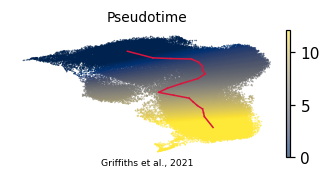

In [9]:
um = adata.obsm['X_umap']
nodexy = np.array([um[hard==k].mean(0) if (hard==k).any() else [np.nan,np.nan] for k in range(B.shape[0])])
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(adata, color='t', cmap='cividis', size=4, alpha=.6, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
for a, b in zip(*np.where(np.triu(B>0))):
    ax.plot([nodexy[a,0],nodexy[b,0]], [nodexy[a,1],nodexy[b,1]], '-', color='crimson', lw=1, zorder=6)
ax.set_title('Pseudotime', size=9)
ax.text(.5, -.06, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')

In [10]:
# sanitize epg for h5ad write, then save manifold
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (108658, 21250)
